## Makoma Pilusa
## ST10145212
## RDPA8412
## Research Analysis
## Title: Applying Machine Learning Algorithms to Analyse the Impact of Social Media Usage on Productivity 

### Data Cleaning 

#### Data cleaning will be conducted as the first stage of analysis to asses the quality, completness, and consistency of the dataset before any further analysis is performed. This stage exmaines the structure of the dataset, data types, duplicate records, missing values, categorical values, numerical ranges, and any invalid observations.

#### This stage will help identify data quality issues that could affect the preprocessing, exploratory data anlysis and machine learning modelling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("social_media_vs_productivity.csv")

In [3]:
df.head()

,age,gender,job_type,daily_social_media_time,social_platform_preference,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
0,56,Male,Unemployed,4.180940,Facebook,61,6.753558,8.040464,7.291555,4.0,5.116546,0.419102,8,False,False,4,11,21.927072,6.336688
1,46,Male,Health,3.249603,Twitter,59,9.169296,5.063368,5.165093,7.0,5.103897,0.671519,7,True,True,2,25,0.000000,3.412427
2,32,Male,Finance,NaN,Twitter,57,7.910952,3.861762,3.474053,4.0,8.583222,0.624378,0,True,False,3,17,10.322044,2.474944
3,60,Female,Unemployed,NaN,Facebook,59,6.355027,2.916331,1.774869,6.0,6.052984,1.204540,1,False,False,0,4,23.876616,1.733670
4,25,Male,IT,NaN,Telegram,66,6.214096,8.868753,NaN,7.0,5.405706,1.876254,1,False,True,1,30,10.653519,9.693060


In [4]:
for column in df.columns:
    print(column)

age
gender
job_type
daily_social_media_time
social_platform_preference
number_of_notifications
work_hours_per_day
perceived_productivity_score
actual_productivity_score
stress_level
sleep_hours
screen_time_before_sleep
breaks_during_work
uses_focus_apps
has_digital_wellbeing_enabled
coffee_consumption_per_day
days_feeling_burnout_per_month
weekly_offline_hours
job_satisfaction_score


In [5]:
df.shape

(30000, 19)

In [6]:
df.dtypes

age                                 int64
gender                             object
job_type                           object
daily_social_media_time           float64
social_platform_preference         object
number_of_notifications             int64
work_hours_per_day                float64
perceived_productivity_score      float64
actual_productivity_score         float64
stress_level                      float64
sleep_hours                       float64
screen_time_before_sleep          float64
breaks_during_work                  int64
uses_focus_apps                      bool
has_digital_wellbeing_enabled        bool
coffee_consumption_per_day          int64
days_feeling_burnout_per_month      int64
weekly_offline_hours              float64
job_satisfaction_score            float64
dtype: object

In [7]:
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


#### The dataset has been assesed for duplicate observations and the dataset contains no duplicate values 

In [8]:
empty_rows = df.isnull().all(axis=1).sum()

print("Number of completely empty rows:", empty_rows)

Number of completely empty rows: 0


In [9]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage Missing": (missing_values / len(df)) * 100
})

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

missing_summary

,Missing Values,Percentage Missing
daily_social_media_time,2765,9.216667
perceived_productivity_score,1614,5.380000
actual_productivity_score,2365,7.883333
stress_level,1904,6.346667
sleep_hours,2598,8.660000
screen_time_before_sleep,2211,7.370000
job_satisfaction_score,2730,9.100000


#### The dataset contains no duplicate records and no completely empty observations, indicating that unnecessary duplicated or blank records are not a data-quality concern. 
#### missing values are present across the dataset and therefore require appropriate treatment before machine learning models are developed. Missing predictor values will be handled later using imputation within the preprocessing pipelines.

In [10]:
df["gender"].value_counts(dropna=False)

gender
Male      14452
Female    14370
Other      1178
Name: count, dtype: int64

In [11]:
df["job_type"].value_counts(dropna=False)

job_type
Education     5055
IT            5026
Finance       5017
Student       5012
Unemployed    4958
Health        4932
Name: count, dtype: int64

In [12]:
df["social_platform_preference"].value_counts(dropna=False)

social_platform_preference
TikTok       6096
Telegram     6013
Instagram    6006
Twitter      5964
Facebook     5921
Name: count, dtype: int64

In [13]:
categorical_columns = df.select_dtypes(include=["object"]).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].dropna().unique())


gender
['Male' 'Female' 'Other']

job_type
['Unemployed' 'Health' 'Finance' 'IT' 'Education' 'Student']

social_platform_preference
['Facebook' 'Twitter' 'Telegram' 'TikTok' 'Instagram']


#### Categorical variables are examined by reviewing their frequencies and unique values. This step helps identify inconsistent category labels, unexpected values, spelling differences, or categories that may require consolidation before encoding.

In [14]:
numerical_columns = df.select_dtypes(include=np.number).columns

for column in numerical_columns:
    print(f"\n{column}")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())


age
Minimum: 18
Maximum: 65

daily_social_media_time
Minimum: 0.0
Maximum: 17.973255602826175

number_of_notifications
Minimum: 30
Maximum: 90

work_hours_per_day
Minimum: 0.0
Maximum: 12.0

perceived_productivity_score
Minimum: 2.0002524300446303
Maximum: 8.999375647878052

actual_productivity_score
Minimum: 0.2968118865395523
Maximum: 9.84625801321986

stress_level
Minimum: 1.0
Maximum: 10.0

sleep_hours
Minimum: 3.0
Maximum: 10.0

screen_time_before_sleep
Minimum: 0.0
Maximum: 3.0

breaks_during_work
Minimum: 0
Maximum: 10

coffee_consumption_per_day
Minimum: 0
Maximum: 10

days_feeling_burnout_per_month
Minimum: 0
Maximum: 31

weekly_offline_hours
Minimum: 0.0
Maximum: 40.96476891751684

job_satisfaction_score
Minimum: 0.0
Maximum: 10.0


In [15]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

print("\nRecords with age below 18:")
print(df[df["age"] < 18])

print("\nRecords with age above 100:")
print(df[df["age"] > 100])

Minimum age: 18
Maximum age: 65

Records with age below 18:
Empty DataFrame
Columns: [age, gender, job_type, daily_social_media_time, social_platform_preference, number_of_notifications, work_hours_per_day, perceived_productivity_score, actual_productivity_score, stress_level, sleep_hours, screen_time_before_sleep, breaks_during_work, uses_focus_apps, has_digital_wellbeing_enabled, coffee_consumption_per_day, days_feeling_burnout_per_month, weekly_offline_hours, job_satisfaction_score]
Index: []

Records with age above 100:
Empty DataFrame
Columns: [age, gender, job_type, daily_social_media_time, social_platform_preference, number_of_notifications, work_hours_per_day, perceived_productivity_score, actual_productivity_score, stress_level, sleep_hours, screen_time_before_sleep, breaks_during_work, uses_focus_apps, has_digital_wellbeing_enabled, coffee_consumption_per_day, days_feeling_burnout_per_month, weekly_offline_hours, job_satisfaction_score]
Index: []


#### Numerical variables are examined using their minimum and maximum values to identify potentially invalid or implausible observations.

In [16]:
print("Perceived Productivity Score")
print("Minimum:", df["perceived_productivity_score"].min())
print("Maximum:", df["perceived_productivity_score"].max())

print("\nActual Productivity Score")
print("Minimum:", df["actual_productivity_score"].min())
print("Maximum:", df["actual_productivity_score"].max())

Perceived Productivity Score
Minimum: 2.0002524300446303
Maximum: 8.999375647878052

Actual Productivity Score
Minimum: 0.2968118865395523
Maximum: 9.84625801321986


In [17]:
numeric_df = df.select_dtypes(include=np.number)

negative_values = (numeric_df < 0).sum()

negative_values = negative_values[negative_values > 0]

print("Variables containing negative values:")
print(negative_values)

Variables containing negative values:
Series([], dtype: int64)


In [18]:
print("DATA CLEANING SUMMARY")
print("=" * 40)

print("Number of records:", df.shape[0])
print("Number of variables:", df.shape[1])
print("Duplicate records:", df.duplicated().sum())
print("Completely empty rows:", df.isnull().all(axis=1).sum())
print("Total missing values:", df.isnull().sum().sum())

DATA CLEANING SUMMARY
Number of records: 30000
Number of variables: 19
Duplicate records: 0
Completely empty rows: 0
Total missing values: 16187


#### The final data-cleaning assessment consolidates the main findings regarding dataset size, duplicate records, empty observations, and missing data. The dataset contains 30,000 observations and 19 variables, with no duplicate or completely empty records identified. 

In [19]:
df.to_csv("social_media_productivity_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


### Data Preprocessing

In [ ]:
#### Following the data-quality assessment, preprocessing is performed to transform the dataset into a suitable format for machine learning. This stage is important because the dataset contains numerical, categorical, and Boolean variables as well as missing observations.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [21]:
target = "actual_productivity_score"

print("Target variable:", target)
print("Missing target values:", df[target].isna().sum())

Target variable: actual_productivity_score
Missing target values: 2365


In [22]:
df_model = df.dropna(subset=[target]).copy()

print("Original number of rows:", len(df))
print("Rows after removing missing target:", len(df_model))
print("Rows removed:", len(df) - len(df_model))

Original number of rows: 30000
Rows after removing missing target: 27635
Rows removed: 2365


In [23]:
leakage_variables = ["perceived_productivity_score"]

X = df_model.drop(columns=[target] + leakage_variables)
y = df_model[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (27635, 17)
y shape: (27635,)


#### The dependent variable for the study is actual_productivity_score, which represents the productivity outcome that the machine learning models aim to predict.

#### The variable perceived_productivity_score is deliberately excluded from the predictor set because it represents an individual's perception of the same underlying productivity concept being predicted.

In [24]:
categorical_features = [
    "gender",
    "job_type",
    "social_platform_preference"
]

boolean_features = [
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

numerical_features = [
    "age",
    "daily_social_media_time",
    "number_of_notifications",
    "work_hours_per_day",
    "stress_level",
    "sleep_hours",
    "screen_time_before_sleep",
    "breaks_during_work",
    "coffee_consumption_per_day",
    "days_feeling_burnout_per_month",
    "weekly_offline_hours",
    "job_satisfaction_score"
]

In [25]:
all_selected_features = (
    numerical_features +
    categorical_features +
    boolean_features
)

print("Number of selected predictors:", len(all_selected_features))

print("\nMissing from feature list:")
print(set(X.columns) - set(all_selected_features))

print("\nUnexpected features:")
print(set(all_selected_features) - set(X.columns))

Number of selected predictors: 17

Missing from feature list:
set()

Unexpected features:
set()


#### The remaining predictors are classified as numerical, categorical, or Boolean variables/features. This classification is required because different data types require different preprocessing procedures.

In [26]:
for column in boolean_features:
    X[column] = X[column].astype(int)

print(X[boolean_features].dtypes)

uses_focus_apps                  int64
has_digital_wellbeing_enabled    int64
dtype: object


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training X:", X_train.shape)
print("Testing X:", X_test.shape)

print("Training y:", y_train.shape)
print("Testing y:", y_test.shape)

Training X: (22108, 17)
Testing X: (5527, 17)
Training y: (22108,)
Testing y: (5527,)


#### The dataset is divided into training and testing subsets using an 80/20 split. A fixed random_state of 42 is used to ensure that the split is reproducible.

In [28]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [29]:
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

In [30]:
boolean_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ]
)

In [31]:
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("boolean", boolean_pipeline, boolean_features)
    ]
)

#### Separate preprocessing pipelines are constructed for numerical, categorical, and Boolean variables. 

In [32]:
X_train_processed = preprocessor_scaled.fit_transform(X_train)

X_test_processed = preprocessor_scaled.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (22108, 25)
Processed testing shape: (5527, 25)


In [33]:
feature_names = preprocessor_scaled.get_feature_names_out()

print("Number of final features:", len(feature_names))

for feature in feature_names:
    print(feature)

Number of final features: 25
numeric__age
numeric__daily_social_media_time
numeric__number_of_notifications
numeric__work_hours_per_day
numeric__stress_level
numeric__sleep_hours
numeric__screen_time_before_sleep
numeric__breaks_during_work
numeric__coffee_consumption_per_day
numeric__days_feeling_burnout_per_month
numeric__weekly_offline_hours
numeric__job_satisfaction_score
categorical__gender_Male
categorical__gender_Other
categorical__job_type_Finance
categorical__job_type_Health
categorical__job_type_IT
categorical__job_type_Student
categorical__job_type_Unemployed
categorical__social_platform_preference_Instagram
categorical__social_platform_preference_Telegram
categorical__social_platform_preference_TikTok
categorical__social_platform_preference_Twitter
boolean__uses_focus_apps
boolean__has_digital_wellbeing_enabled


In [34]:
X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed training dataset:")
print(X_train_processed_df.shape)

print("\nProcessed testing dataset:")
print(X_test_processed_df.shape)

Processed training dataset:
(22108, 25)

Processed testing dataset:
(5527, 25)


In [35]:
print(
    "Missing values in processed training data:",
    X_train_processed_df.isna().sum().sum()
)

print(
    "Missing values in processed testing data:",
    X_test_processed_df.isna().sum().sum()
)

Missing values in processed training data: 0
Missing values in processed testing data: 0


In [36]:
print("Missing values in y_train:", y_train.isna().sum())
print("Missing values in y_test:", y_test.isna().sum())

Missing values in y_train: 0
Missing values in y_test: 0


#### Following transformation, the training dataset contains 22,108 observations and the test dataset contains 5,527 observations. The original predictors are transformed into 25 model-ready features after categorical encoding.

In [37]:
conda install statsmodels

Jupyter detected...
3 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - defaults
Platform: win-64
Solving environment: done

## Package Plan ##

  environment location: C:\Users\makom\anaconda3

  added / updated specs:
    - statsmodels


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.10.20 |       h382c6e5_1         113 KB
    certifi-2026.10.23         |     pyhd3eb1b0_1         131 KB
    openssl-3.5.9              |       hbb43b14_0         8.9 MB
    ------------------------------------------------------------
                                           Total:         9.1 MB

The following packages will be UPDATED:

  ca-certificates    pkgs/main/win-64::ca-certificates-202~ --> pkgs/main/noarch::ca-certificates-2026.10.20-h382c6e5_1 
  certifi            pkgs/main/win-64::certifi-2026.7.22-p~ --> pkgs/main/noarch::certifi-2026.10.23-pyhd3



==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.9.4

Please update conda by running

    $ conda update -n base -c defaults conda



# >>>>>>>>>>>>>>>>>>>>>> ERROR REPORT <<<<<<<<<<<<<<<<<<<<<<

    Traceback (most recent call last):
      File "C:\Users\makom\anaconda3\Lib\site-packages\conda\gateways\disk\delete.py", line 144, in unlink_or_rename_to_trash
        os.unlink(path)
        ~~~~~~~~~^^^^^^
    PermissionError: [WinError 5] Access is denied: 'C:\\Users\\makom\\anaconda3\\Library\\bin\\libcrypto-3-x64.dll.c~'
    
    During handling of the above exception, another exception occurred:
    
    Traceback (most recent call last):
      File "C:\Users\makom\anaconda3\Lib\site-packages\conda\gateways\disk\delete.py", line 147, in unlink_or_rename_to_trash
        os.rename(path, path + ".conda_trash")
        ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    FileExistsError: [WinError 183] Cannot create a file when that file alre

In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [39]:
vif_data = X[numerical_features].copy()

# Impute using median for the VIF assessment
vif_data = vif_data.fillna(vif_data.median())

# Add intercept
vif_with_constant = sm.add_constant(vif_data)

vif_results = pd.DataFrame()

vif_results["Variable"] = vif_with_constant.columns

vif_results["VIF"] = [
    variance_inflation_factor(
        vif_with_constant.values,
        i
    )
    for i in range(vif_with_constant.shape[1])
]

vif_results

,Variable,VIF
0,const,1.000000
1,age,1.000524
2,daily_social_media_time,1.000331
3,number_of_notifications,1.000633
4,work_hours_per_day,1.000406
5,stress_level,1.000078
6,sleep_hours,1.000377
7,screen_time_before_sleep,1.000351
8,breaks_during_work,1.000586
9,coffee_consumption_per_day,1.000236


#### Variance Inflation Factor (VIF) analysis is performed on the numerical predictors to assess multicollinearity.

In [40]:
outlier_results = []

for column in numerical_features:

    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "Variable": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outliers
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Variable,Lower Bound,Upper Bound,Potential Outliers
0,age,-4.500000,87.500000,0
1,daily_social_media_time,-2.480140,8.488677,196
2,number_of_notifications,40.000000,80.000000,244
3,work_hours_per_day,1.574654,12.423226,88
4,stress_level,-4.500000,15.500000,0
5,sleep_hours,2.489440,10.507327,0
6,screen_time_before_sleep,-0.904089,2.911723,90
7,breaks_during_work,-7.000000,17.000000,0
8,coffee_consumption_per_day,-2.000000,6.000000,118
9,days_feeling_burnout_per_month,-16.000000,48.000000,0


#### Potential outliers are identified using the Interquartile Range (IQR) method. Observations below 1.5 IQRs from the first quartile or above 1.5 IQRs from the third quartile are flagged for further assessment. The purpose of this procedure is to identify unusually high or low observations rather than automatically remove them

In [41]:
print("=" * 60)
print("FINAL PREPROCESSING CHECK")
print("=" * 60)

print("Original dataset:", df.shape)

print("Dataset after target removal:", df_model.shape)

print("Number of predictors:", X.shape[1])

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

print("Processed training features:", X_train_processed_df.shape[1])
print("Processed testing features:", X_test_processed_df.shape[1])

print("Missing values in processed training data:",
      X_train_processed_df.isna().sum().sum())

print("Missing values in processed testing data:",
      X_test_processed_df.isna().sum().sum())

print("Target variable:", target)

FINAL PREPROCESSING CHECK
Original dataset: (30000, 19)
Dataset after target removal: (27635, 19)
Number of predictors: 17
Training observations: 22108
Testing observations: 5527
Processed training features: 25
Processed testing features: 25
Missing values in processed training data: 0
Missing values in processed testing data: 0
Target variable: actual_productivity_score


### Exploratory Data Analysis

#### Exploratory Data Analysis (EDA) is conducted to develop a deeper understanding of the characteristics and relationships within the modelling dataset before machine learning models are developed.

In [42]:
from scipy import stats

In [43]:
# Remove rows where the target is missing
df_model = df.dropna(
    subset=["actual_productivity_score"]
).copy()

# Remove target leakage from analysis
df_model = df_model.drop(
    columns=["perceived_productivity_score"]
)

print("Final EDA dataset:", df_model.shape)

Final EDA dataset: (27635, 18)


In [44]:
print(df_model.info())

print("\nColumns:")
for column in df_model.columns:
    print(column)

<class 'pandas.core.frame.DataFrame'>
Index: 27635 entries, 0 to 29999
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             27635 non-null  int64  
 1   gender                          27635 non-null  object 
 2   job_type                        27635 non-null  object 
 3   daily_social_media_time         25095 non-null  float64
 4   social_platform_preference      27635 non-null  object 
 5   number_of_notifications         27635 non-null  int64  
 6   work_hours_per_day              27635 non-null  float64
 7   actual_productivity_score       27635 non-null  float64
 8   stress_level                    25880 non-null  float64
 9   sleep_hours                     25217 non-null  float64
 10  screen_time_before_sleep        25593 non-null  float64
 11  breaks_during_work              27635 non-null  int64  
 12  uses_focus_apps                 27635

In [45]:
numeric_columns = df_model.select_dtypes(
    include=np.number
).columns

descriptive_stats = df_model[numeric_columns].describe().T

descriptive_stats["median"] = (
    df_model[numeric_columns].median()
)

descriptive_stats["IQR"] = (
    descriptive_stats["75%"] -
    descriptive_stats["25%"]
)

descriptive_stats = descriptive_stats[
    [
        "mean",
        "median",
        "std",
        "min",
        "25%",
        "75%",
        "max",
        "IQR"
    ]
]

descriptive_stats.round(3)

,mean,median,std,min,25%,75%,max,IQR
age,41.480,41.000,13.842,18.000,30.000,53.000,65.000,23.000
daily_social_media_time,3.114,3.028,2.076,0.000,1.633,4.375,17.973,2.742
number_of_notifications,59.954,60.000,7.727,30.000,55.000,65.000,90.000,10.000
work_hours_per_day,6.990,6.988,1.999,0.000,5.643,8.355,12.000,2.712
actual_productivity_score,4.952,4.952,1.883,0.297,3.373,6.526,9.846,3.153
stress_level,5.521,6.000,2.866,1.000,3.000,8.000,10.000,5.000
sleep_hours,6.501,6.497,1.460,3.000,5.496,7.501,10.000,2.004
screen_time_before_sleep,1.027,1.007,0.655,0.000,0.527,1.481,3.000,0.954
breaks_during_work,4.988,5.000,3.175,0.000,2.000,8.000,10.000,6.000
coffee_consumption_per_day,2.003,2.000,1.410,0.000,1.000,3.000,10.000,2.000


#### Descriptive statistics are calculated to summarise the central tendency, variability, and range of the numerical variables. Measures including the mean, median, standard deviation, minimum, maximum, quartiles, and interquartile range provide an overview of the distribution of each variable.

In [46]:
categorical_columns = [
    "gender",
    "job_type",
    "social_platform_preference",
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

for column in categorical_columns:

    print("\n" + "=" * 50)
    print(column)

    summary = pd.DataFrame({
        "Frequency": df_model[column].value_counts(),
        "Percentage": (
            df_model[column]
            .value_counts(normalize=True) * 100
        ).round(2)
    })

    print(summary)
    print("Unique categories:",
          df_model[column].nunique())


gender
        Frequency  Percentage
gender                       
Male        13316       48.19
Female      13245       47.93
Other        1074        3.89
Unique categories: 3

job_type
            Frequency  Percentage
job_type                         
Education        4667       16.89
Finance          4639       16.79
IT               4618       16.71
Student          4616       16.70
Unemployed       4555       16.48
Health           4540       16.43
Unique categories: 6

social_platform_preference
                            Frequency  Percentage
social_platform_preference                       
TikTok                           5624       20.35
Instagram                        5543       20.06
Twitter                          5513       19.95
Telegram                         5487       19.86
Facebook                         5468       19.79
Unique categories: 5

uses_focus_apps
                 Frequency  Percentage
uses_focus_apps                       
False                193

#### The categorical distributions indicate relatively balanced representation across several important groups. Male and female observations each account for about 48% of the analysed sample, while the different job categories each represent approximately 16–17%.  

In [47]:
target = "actual_productivity_score"

print("Mean:", df_model[target].mean())
print("Median:", df_model[target].median())
print("Standard deviation:", df_model[target].std())
print("Minimum:", df_model[target].min())
print("Maximum:", df_model[target].max())
print("Skewness:", df_model[target].skew())

Mean: 4.951804879665391
Median: 4.951741600417723
Standard deviation: 1.883378033333406
Minimum: 0.2968118865395523
Maximum: 9.84625801321986
Skewness: -0.006767647280579564


#### The distribution of actual_productivity_score is examined using descriptive statistics, a histogram, and a boxplot. Understanding the target distribution is important because extreme skewness, unusual values, or severe outliers could influence regression model performance.

#### Actual productivity scores are distributed around a mean and median of  4.95, with a standard deviation of 1.88. The skewness value of −0.007 is extremely close to zero, indicating a symmetrical distribution. The similarity between the mean and median provides additional evidence that the productivity scores are not strongly skewed.

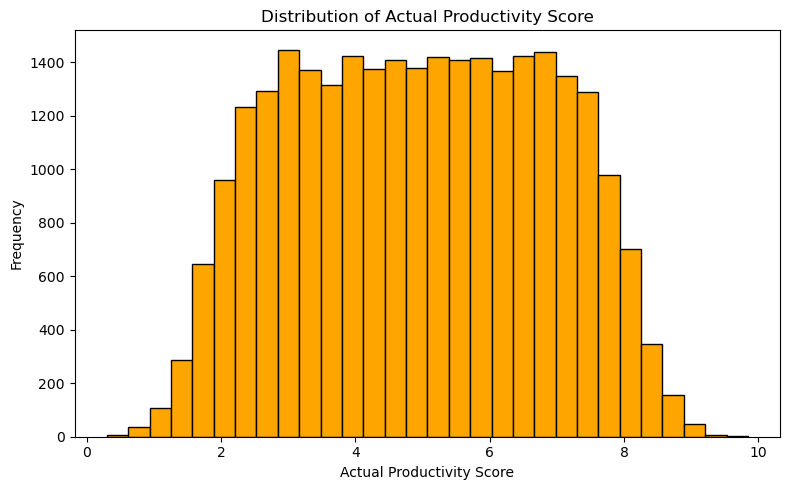

In [48]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_model[target],
    bins=30,
    color="Orange",
    edgecolor="black"
)

plt.xlabel("Actual Productivity Score")
plt.ylabel("Frequency")
plt.title("Distribution of Actual Productivity Score")

plt.tight_layout()
plt.show()

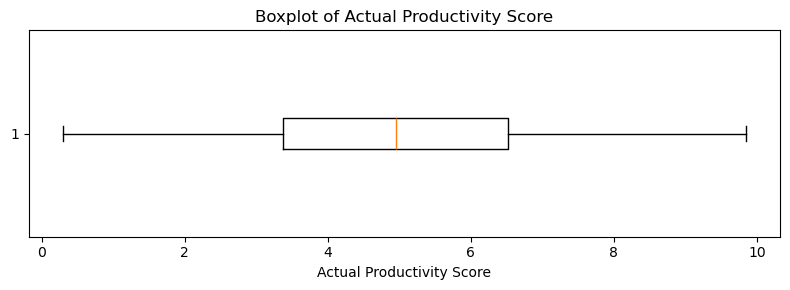

In [49]:
plt.figure(figsize=(8, 3))

plt.boxplot(
    df_model[target],
    vert=False
)

plt.xlabel("Actual Productivity Score")
plt.title("Boxplot of Actual Productivity Score")

plt.tight_layout()
plt.show()

#### The boxplot confirms that actual productivity scores are broadly distributed without obvious extreme IQR-based outliers. 

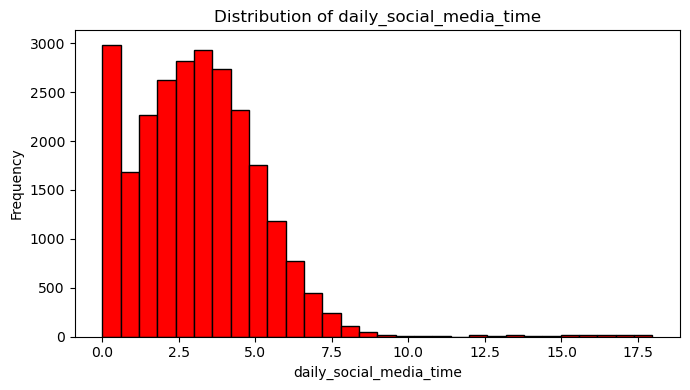

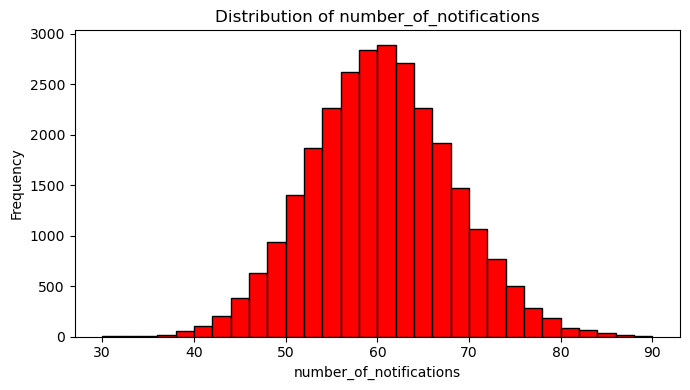

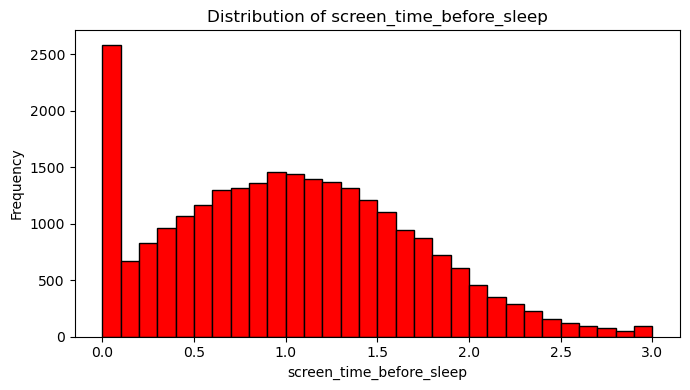

In [50]:
social_numeric = [
    "daily_social_media_time",
    "number_of_notifications",
    "screen_time_before_sleep"
]

for column in social_numeric:

    plt.figure(figsize=(7, 4))

    plt.hist(
        df_model[column].dropna(),
        bins=30,
        color= "red",
        edgecolor="black"
    )

    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.title(
        f"Distribution of {column}"
    )

    plt.tight_layout()
    plt.show()

#### Histograms are used to examine the distributions of three central digital-behaviour variables: daily social-media time, number of notifications, and screen time before sleep. These variables represent different dimensions of social-media exposure and digital engagement and are therefore particularly relevant to the study's research questions.

#### Participants receive an average of approximately 60 notifications, while screen time before sleep averages 1 hour. The distributions demonstrate meaningful variation in digital behaviour across observations, providing sufficient variation for investigating whether these factors are associated with differences in productivity.

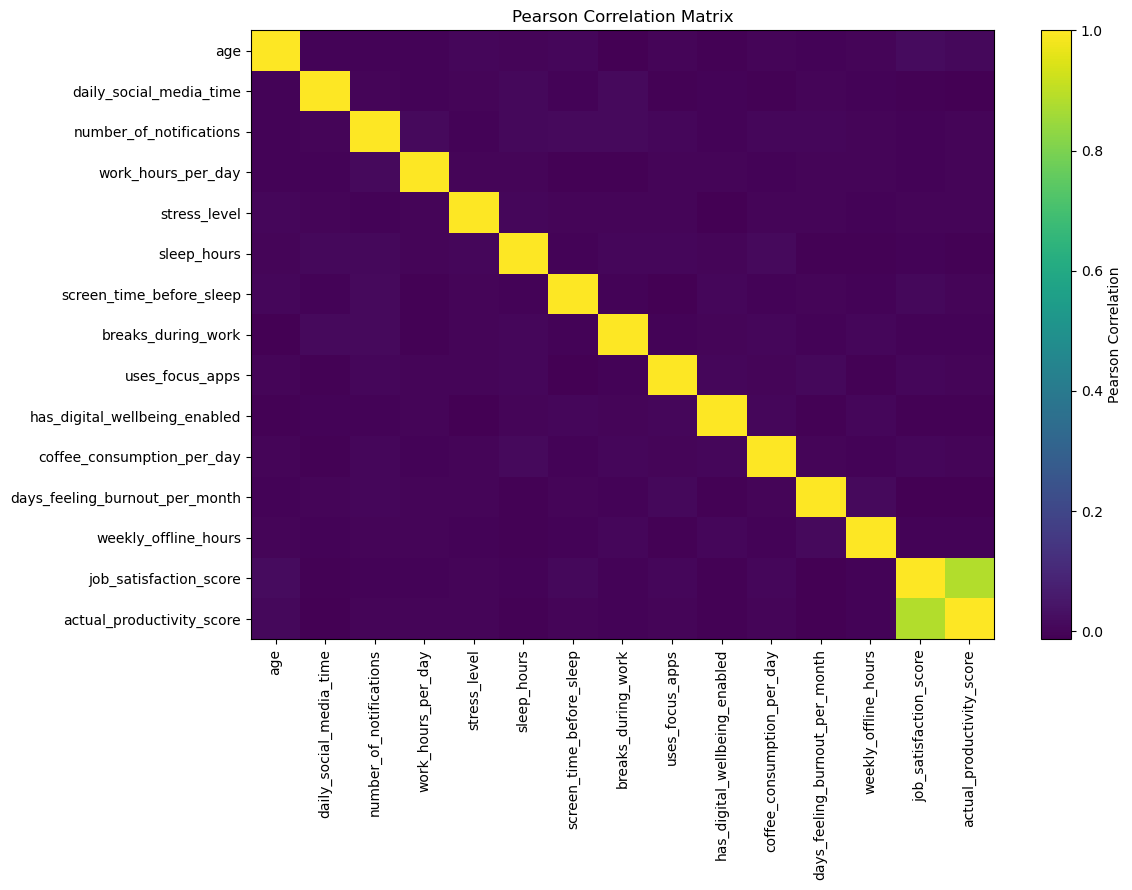

In [51]:
correlation_columns = [
    "age",
    "daily_social_media_time",
    "number_of_notifications",
    "work_hours_per_day",
    "stress_level",
    "sleep_hours",
    "screen_time_before_sleep",
    "breaks_during_work",
    "uses_focus_apps",
    "has_digital_wellbeing_enabled",
    "coffee_consumption_per_day",
    "days_feeling_burnout_per_month",
    "weekly_offline_hours",
    "job_satisfaction_score",
    "actual_productivity_score"
]

correlation_matrix = df_model[
    correlation_columns
].corr(method="pearson")

plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title(
    "Pearson Correlation Matrix"
)

plt.tight_layout()
plt.show()

#### A Pearson correlation matrix is used to examine the direction and strength of linear relationships between numerical variables. Particular attention is given to correlations between actual_productivity_score and variables representing social-media behaviour, digital habits, lifestyle characteristics, and work-related factors

#### The correlation analysis identifies job_satisfaction_score as the strongest numerical correlate of actual productivity.

In [52]:
target_correlations = (
    correlation_matrix["actual_productivity_score"]
    .drop("actual_productivity_score")
    .sort_values(
        key=abs,
        ascending=False
    )
)

print(target_correlations.round(3))

job_satisfaction_score            0.883
days_feeling_burnout_per_month   -0.011
daily_social_media_time          -0.011
age                               0.011
sleep_hours                      -0.008
has_digital_wellbeing_enabled    -0.007
weekly_offline_hours             -0.005
breaks_during_work               -0.004
screen_time_before_sleep          0.002
stress_level                      0.001
coffee_consumption_per_day        0.001
uses_focus_apps                  -0.001
number_of_notifications           0.000
work_hours_per_day               -0.000
Name: actual_productivity_score, dtype: float64


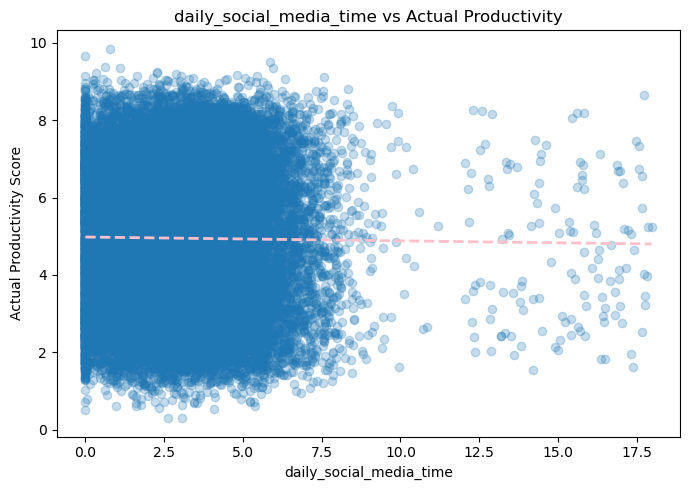

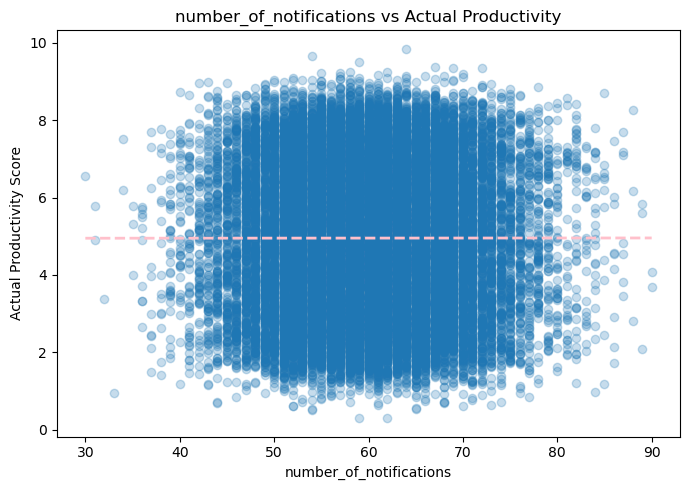

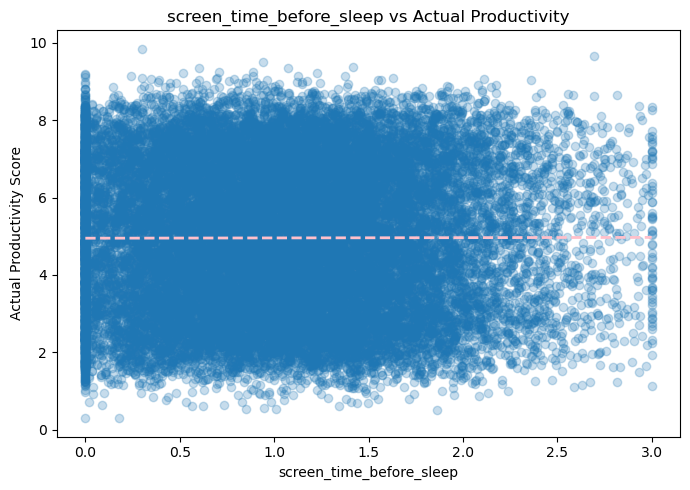

In [54]:
for column in social_numeric:

    plt.figure(figsize=(7, 5))

    valid = df_model[
        [column, target]
    ].dropna()

    plt.scatter(
        valid[column],
        valid[target],
        alpha=0.25
    )

    #Trend line
    slope, intercept = np.polyfit(
        valid[column],
        valid[target],
        1,
        
    )

    x_values = np.linspace(
        valid[column].min(),
        valid[column].max(),
        100
    )

    y_values = (
        slope * x_values +
        intercept
    )

    plt.plot(
        x_values,
        y_values,
        color = "pink",
        linestyle="--",
        linewidth=2
    )

    plt.xlabel(column)
    plt.ylabel("Actual Productivity Score")

    plt.title(
        f"{column} vs Actual Productivity"
    )

    plt.tight_layout()
    plt.show()

#### Scatterplots are used to visually examine the relationships between continuous social-media variables and actual productivity. These graphs complement the numerical correlation analysis by allowing potential nonlinear patterns, clustering, and unusual observations to be identified visually

#### The scatterplots show dispersion in productivity scores across the observed ranges of daily social-media time, notification frequency, and screen time before sleep. No clear upward or downward linear pattern is visually apparent for these variables. This is consistent with the near-zero Pearson correlations observed previously and suggests that none of these variables has a strong independent linear relationship with actual productivity.

C:\Users\makom\AppData\Local\Temp\ipykernel_9604\3357482822.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


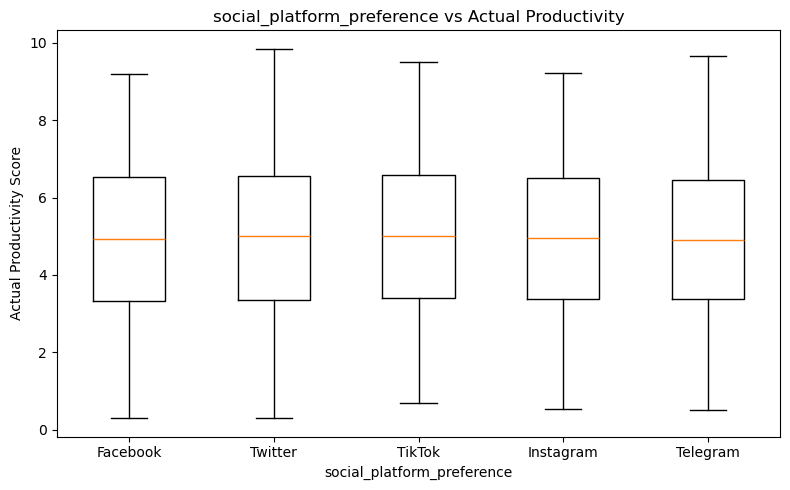

C:\Users\makom\AppData\Local\Temp\ipykernel_9604\3357482822.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


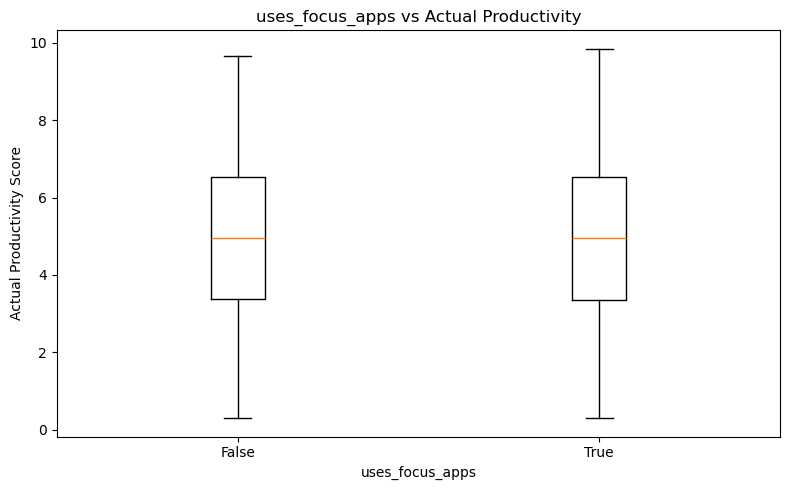

C:\Users\makom\AppData\Local\Temp\ipykernel_9604\3357482822.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


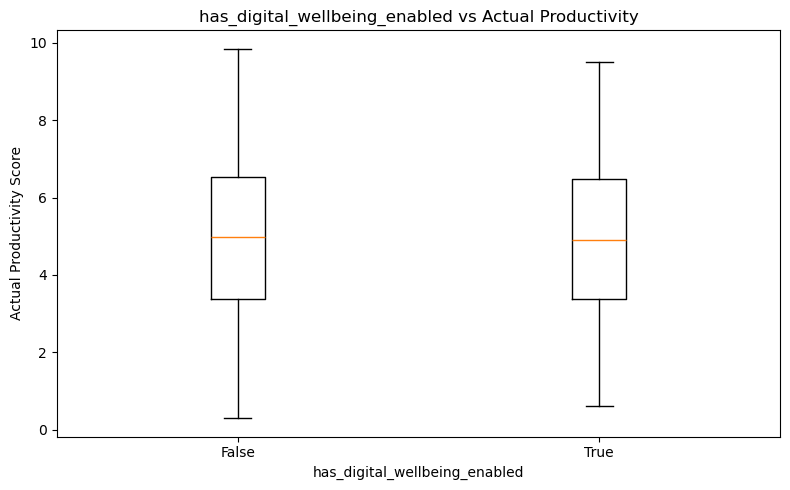

In [55]:
categorical_productivity = [
    "social_platform_preference",
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

for column in categorical_productivity:

    categories = (
        df_model[column]
        .dropna()
        .unique()
    )

    data = [
        df_model.loc[
            df_model[column] == category,
            target
        ].dropna()
        for category in categories
    ]

    plt.figure(figsize=(8, 5))

    plt.boxplot(
        data,
        labels=categories
    )

    plt.xlabel(column)
    plt.ylabel("Actual Productivity Score")

    plt.title(
        f"{column} vs Actual Productivity"
    )

    plt.tight_layout()
    plt.show()

#### Boxplots are used to compare the distribution of actual productivity across social-platform preference, focus-application usage, and digital-wellbeing settings.

In [56]:
outlier_results = []

for column in numeric_columns:

    Q1 = df_model[column].quantile(0.25)
    Q3 = df_model[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    number_outliers = (
        (df_model[column] < lower) |
        (df_model[column] > upper)
    ).sum()

    outlier_results.append({
        "Variable": column,
        "Potential Outliers": number_outliers,
        "Percentage": (
            number_outliers /
            len(df_model) * 100
        )
    })

outlier_table = pd.DataFrame(
    outlier_results
)

outlier_table.sort_values(
    "Potential Outliers",
    ascending=False
)

,Variable,Potential Outliers,Percentage
2,number_of_notifications,244,0.882938
1,daily_social_media_time,196,0.709246
9,coffee_consumption_per_day,118,0.426995
11,weekly_offline_hours,106,0.383572
7,screen_time_before_sleep,90,0.325674
3,work_hours_per_day,88,0.318437
0,age,0,0.000000
4,actual_productivity_score,0,0.000000
5,stress_level,0,0.000000
6,sleep_hours,0,0.000000


### Feature Selection and Modelling

#### Following preprocessing and exploratory analysis, machine learning models are developed to determine how effectively productivity can be predicted from the available behavioural, digital, lifestyle, demographic, and work-related characteristics.

In [57]:
## Imports
import seaborn as sns

from sklearn.model_selection import (train_test_split, KFold, GridSearchCV, cross_validate)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, OneHotEncoder)
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE

from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error)

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [58]:
df = pd.read_csv("social_media_vs_productivity.csv")

print("Original dataset shape:", df.shape)

Original dataset shape: (30000, 19)


In [59]:
TARGET = "actual_productivity_score"

# Remove rows where the target is missing
df_model = df.dropna(subset=[TARGET]).copy()

print("Modelling dataset shape:", df_model.shape)

Modelling dataset shape: (27635, 19)


In [60]:
LEAKAGE_FEATURES = [
    "perceived_productivity_score"
]

X = df_model.drop(
    columns=[TARGET] + LEAKAGE_FEATURES
)

y = df_model[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (27635, 17)
y shape: (27635,)


In [61]:
## Variables
social_media_features = [
    "daily_social_media_time",
    "number_of_notifications",
    "social_platform_preference"
]

digital_behaviour_features = [
    "screen_time_before_sleep",
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

behavioural_features = [
    "work_hours_per_day",
    "stress_level",
    "breaks_during_work",
    "days_feeling_burnout_per_month",
    "job_satisfaction_score"
]

lifestyle_features = [
    "sleep_hours",
    "coffee_consumption_per_day",
    "weekly_offline_hours"
]

demographic_context_features = [
    "age",
    "gender",
    "job_type"
]

In [62]:
boolean_features = [
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

# Convert Booleans to 0/1
for column in boolean_features:
    X[column] = X[column].astype(int)

print(X[boolean_features].dtypes)
print(X[boolean_features].head())

uses_focus_apps                  int64
has_digital_wellbeing_enabled    int64
dtype: object
   uses_focus_apps  has_digital_wellbeing_enabled
0                0                              0
1                1                              1
2                1                              0
3                0                              0
5                0                              1


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (22108, 17)
Testing set: (5527, 17)


In [64]:
categorical_features = [
    "gender",
    "job_type",
    "social_platform_preference"
]

boolean_features = [
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

numerical_features = [
    "age",
    "daily_social_media_time",
    "number_of_notifications",
    "work_hours_per_day",
    "stress_level",
    "sleep_hours",
    "screen_time_before_sleep",
    "breaks_during_work",
    "coffee_consumption_per_day",
    "days_feeling_burnout_per_month",
    "weekly_offline_hours",
    "job_satisfaction_score"
]

In [65]:
numerical_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numerical_pipeline_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

boolean_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

In [66]:
preprocessor_scaled = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline_scaled,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
    (
        "boolean",
        boolean_pipeline,
        boolean_features
    )
])

In [67]:
preprocessor_tree = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline_unscaled,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
    (
        "boolean",
        boolean_pipeline,
        boolean_features
    )
])

In [136]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_r2 = r2_score(y_test, baseline_predictions)
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_mse = mean_squared_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(baseline_mse)

print("Baseline R2:", baseline_r2)
print("Baseline MAE:", baseline_mae)
print("Baseline MSE:", baseline_mse)
print("Baseline RMSE:", baseline_rmse)

Baseline R2: -8.619996899583704e-05
Baseline MAE: 1.6283946130695157
Baseline MSE: 3.6028518227259365
Baseline RMSE: 1.8981179686009868


#### The baseline model produces an R2 value equal to zero and an RMSE of approximately 1.898. This is expected because the model simply predicts the mean productivity score rather than learning relationships between the predictors and productivity. 

In [69]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [70]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", LinearRegression())
])

linear_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [138]:
linear_cv = cross_validate(
    linear_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "neg_mae": "neg_mean_absolute_error",
        "neg_mse": "neg_mean_squared_error",
        "neg_rmse": "neg_root_mean_squared_error"
    },
    return_train_score=True
)

print("Linear Regression")
print("Mean Cross Validation R2:", linear_cv["test_r2"].mean())
print("Cross Validation R2 SD:", linear_cv["test_r2"].std())
print(
    "Mean Cross Validation RMSE:",
    -linear_cv["test_neg_rmse"].mean()
)
print(
    "Cross Validation RMSE SD:",
    (-linear_cv["test_neg_rmse"]).std()
)

Linear Regression
Mean Cross Validation R2: 0.708798051968946
Cross Validation R2 SD: 0.007859251388090755
Mean Cross Validation RMSE: 1.0138833942045398
Cross Validation RMSE SD: 0.014572525710476302


#### Linear Regression is used as the first predictive algorithm and provides an interpretable benchmark for modelling the relationship between the predictors and actual productivity. The scaled preprocessing pipeline is incorporated directly into the model pipeline to ensure that preprocessing is applied consistently during training and validation.


In [72]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    (
        "model",
        RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

In [73]:
rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt"]
}

In [74]:
rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True,
    verbose = 2
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("Best Cross Validation RMSE:")
print(-rf_grid.best_score_)

# Saving best
best_rf = rf_grid.best_estimator_

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest parameters:
{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best Cross Validation RMSE:
1.0335845976877962


In [75]:
!pip install xgboost

In [76]:
from xgboost import XGBRegressor

In [77]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    (
        "model",
        XGBRegressor(
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

In [78]:
xgb_params = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

In [79]:
xgb_grid = GridSearchCV(
    xgb_pipeline,
    xgb_params,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True,
    verbose = 2
)

xgb_grid.fit(X_train, y_train)

print("Best XGBoost parameters:")
print(xgb_grid.best_params_)

print("Best Cross Validation RMSE:")
print(-xgb_grid.best_score_)

# Saving best
best_xgb = xgb_grid.best_estimator_

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best XGBoost parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best Cross Validation RMSE:
1.000760174549554


In [80]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results = {
        "Model": name,

        "Training R²": r2_score(
            y_train,
            train_pred
        ),

        "Test R²": r2_score(
            y_test,
            test_pred
        ),

        "Training RMSE": np.sqrt(
            mean_squared_error(
                y_train,
                train_pred
            )
        ),

        "Test RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                test_pred
            )
        ),

        "Test MAE": mean_absolute_error(
            y_test,
            test_pred
        ),

        "Test MSE": mean_squared_error(
            y_test,
            test_pred
        )
    }

    return results
    

In [81]:
linear_results = evaluate_model(
    "Linear Regression",
    linear_pipeline,
    X_train,
    y_train,
    X_test,
    y_test
)

rf_results = evaluate_model(
    "Random Forest",
    best_rf,
    X_train,
    y_train,
    X_test,
    y_test
)

xgb_results = evaluate_model(
    "XGBoost",
    best_xgb,
    X_train,
    y_train,
    X_test,
    y_test
)

final_results_df = pd.DataFrame([
    linear_results,
    rf_results,
    xgb_results
])

final_results_df

,Model,Training R²,Test R²,Training RMSE,Test RMSE,Test MAE,Test MSE
0,Linear Regression,0.709569,0.710228,1.012967,1.021721,0.789736,1.043914
1,Random Forest,0.921275,0.701636,0.527389,1.036758,0.809141,1.074868
2,XGBoost,0.721347,0.719058,0.992215,1.006034,0.771942,1.012105


### Evaluating Models

In [83]:
final_models = {
    "Linear Regression": linear_pipeline,
    "Random Forest": rf_grid.best_estimator_,
    "XGBoost": xgb_grid.best_estimator_
}

In [84]:
model_results = []

for name, model in final_models.items():

    result = evaluate_model(
        name,
        model,
        X_train,
        y_train,
        X_test,
        y_test
    )

    model_results.append(result)

model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,Training R²,Test R²,Training RMSE,Test RMSE,Test MAE,Test MSE
0,Linear Regression,0.709569,0.710228,1.012967,1.021721,0.789736,1.043914
1,Random Forest,0.921275,0.701636,0.527389,1.036758,0.809141,1.074868
2,XGBoost,0.721347,0.719058,0.992215,1.006034,0.771942,1.012105


In [145]:
cv_results = []

for name, model in final_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Cross Validation R2 Mean": scores["test_r2"].mean(),
        "Cross Validation R2 SD": scores["test_r2"].std(),
        "Cross Validation RMSE Mean": -scores["test_rmse"].mean(),
        "Cross Validation RMSE SD": (-scores["test_rmse"]).std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Model,Cross Validation R2 Mean,Cross Validation R2 SD,Cross Validation RMSE Mean,Cross Validation RMSE SD
0,Linear Regression,0.708798,0.007859,1.013883,0.014573
1,Random Forest,0.697392,0.007445,1.033585,0.015080
2,XGBoost,0.716289,0.007287,1.000760,0.013305


In [86]:
final_comparison = cv_results_df.merge(
    model_results_df,
    on="Model"
)

final_comparison

,Model,Cross Validation R² Mean,Cross Validation R² SD,Cross Validation RMSE Mean,Cross Validation RMSE SD,Training R²,Test R²,Training RMSE,Test RMSE,Test MAE,Test MSE
0,Linear Regression,0.708798,0.007859,1.013883,0.014573,0.709569,0.710228,1.012967,1.021721,0.789736,1.043914
1,Random Forest,0.697392,0.007445,1.033585,0.015080,0.921275,0.701636,0.527389,1.036758,0.809141,1.074868
2,XGBoost,0.716289,0.007287,1.000760,0.013305,0.721347,0.719058,0.992215,1.006034,0.771942,1.012105


In [87]:
final_comparison.sort_values(
    by="Test RMSE"
)

,Model,Cross Validation R² Mean,Cross Validation R² SD,Cross Validation RMSE Mean,Cross Validation RMSE SD,Training R²,Test R²,Training RMSE,Test RMSE,Test MAE,Test MSE
2,XGBoost,0.716289,0.007287,1.000760,0.013305,0.721347,0.719058,0.992215,1.006034,0.771942,1.012105
0,Linear Regression,0.708798,0.007859,1.013883,0.014573,0.709569,0.710228,1.012967,1.021721,0.789736,1.043914
1,Random Forest,0.697392,0.007445,1.033585,0.015080,0.921275,0.701636,0.527389,1.036758,0.809141,1.074868


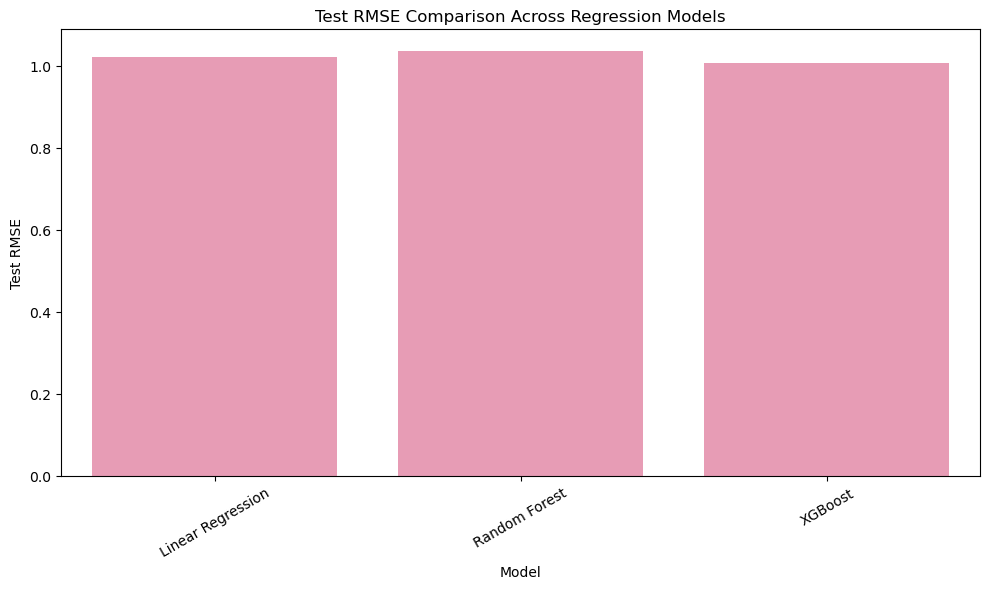

In [88]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_comparison,
    x="Model",
    y="Test RMSE",
    color = "#F48FB1"
)

plt.xticks(rotation=30)
plt.ylabel("Test RMSE")
plt.title("Test RMSE Comparison Across Regression Models")
plt.tight_layout()
plt.show()

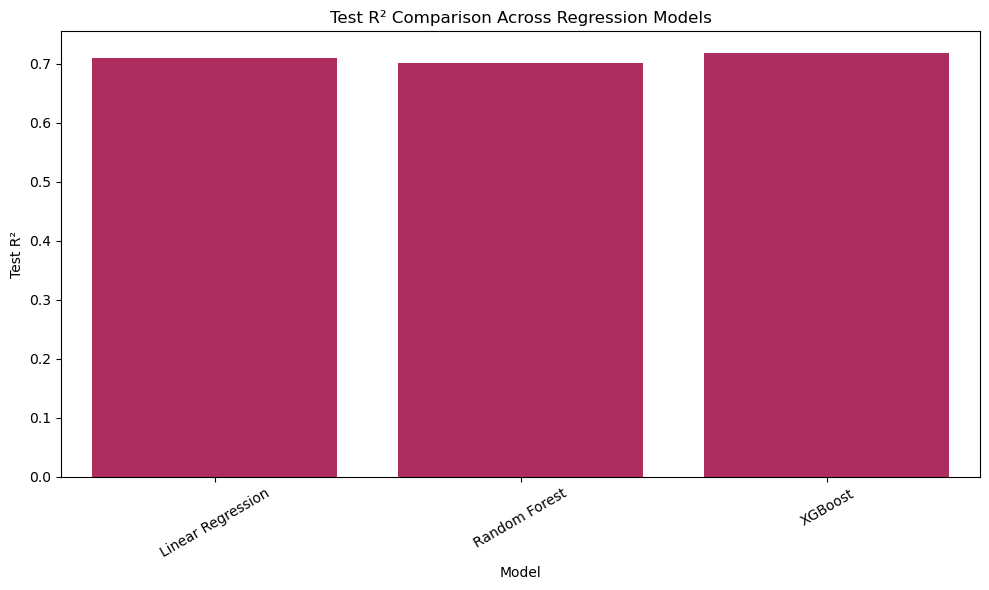

In [89]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_comparison,
    x="Model",
    y="Test R²",
    color = "#C2185B"
)

plt.xticks(rotation=30)
plt.ylabel("Test R²")
plt.title("Test R² Comparison Across Regression Models")
plt.tight_layout()
plt.show()

In [90]:
best_rf = rf_grid.best_estimator_

rf_preprocessor = best_rf.named_steps["preprocessor"]
rf_model = best_rf.named_steps["model"]

rf_feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

rf_importance.head(20)

,Feature,Importance
11,numerical__job_satisfaction_score,0.698735
3,numerical__work_hours_per_day,0.029133
5,numerical__sleep_hours,0.028877
6,numerical__screen_time_before_sleep,0.027955
1,numerical__daily_social_media_time,0.027614
10,numerical__weekly_offline_hours,0.027211
0,numerical__age,0.023761
2,numerical__number_of_notifications,0.023028
9,numerical__days_feeling_burnout_per_month,0.021854
7,numerical__breaks_during_work,0.016784


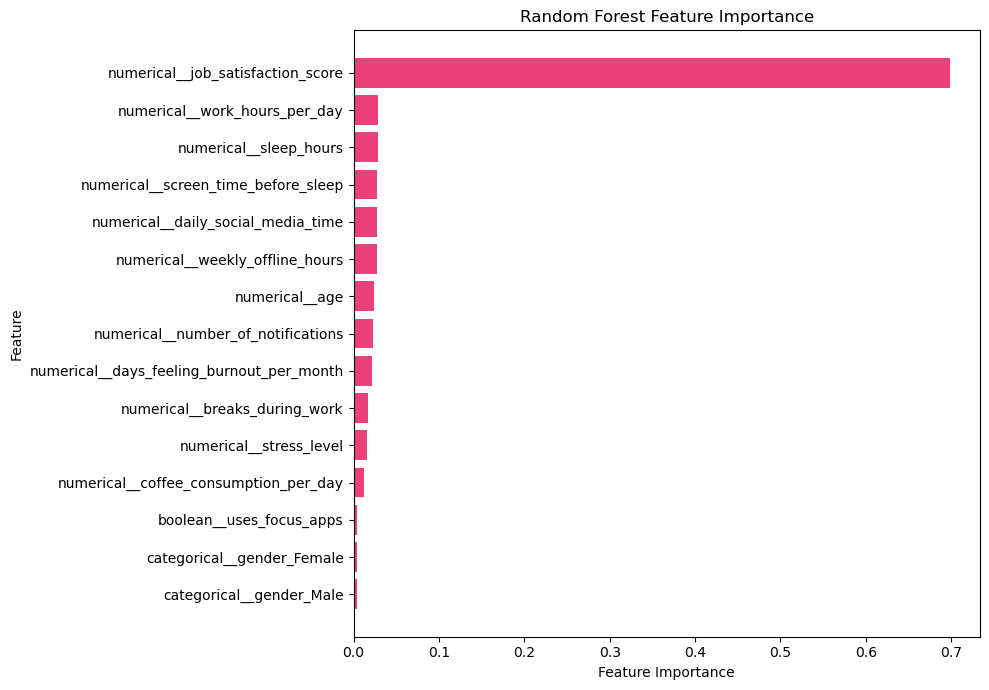

In [91]:
top_rf = rf_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_rf["Feature"],
    top_rf["Importance"],
    color="#EC407A"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [92]:
best_xgb = xgb_grid.best_estimator_

xgb_preprocessor = best_xgb.named_steps["preprocessor"]
xgb_model = best_xgb.named_steps["model"]

xgb_feature_names = (
    xgb_preprocessor
    .get_feature_names_out()
)

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_importance.head(20)

,Feature,Importance
11,numerical__job_satisfaction_score,0.837399
18,categorical__job_type_IT,0.009366
12,categorical__gender_Female,0.008591
3,numerical__work_hours_per_day,0.008138
4,numerical__stress_level,0.007728
13,categorical__gender_Male,0.007566
9,numerical__days_feeling_burnout_per_month,0.007162
8,numerical__coffee_consumption_per_day,0.007138
5,numerical__sleep_hours,0.007028
22,categorical__social_platform_preference_Instagram,0.006683


In [93]:
!pip install shap

In [94]:
import shap

In [95]:
best_model_name = (
    final_comparison
    .sort_values("Test RMSE")
    .iloc[0]["Model"]
)

print("Best model based on test RMSE:", best_model_name)

Best model based on test RMSE: XGBoost


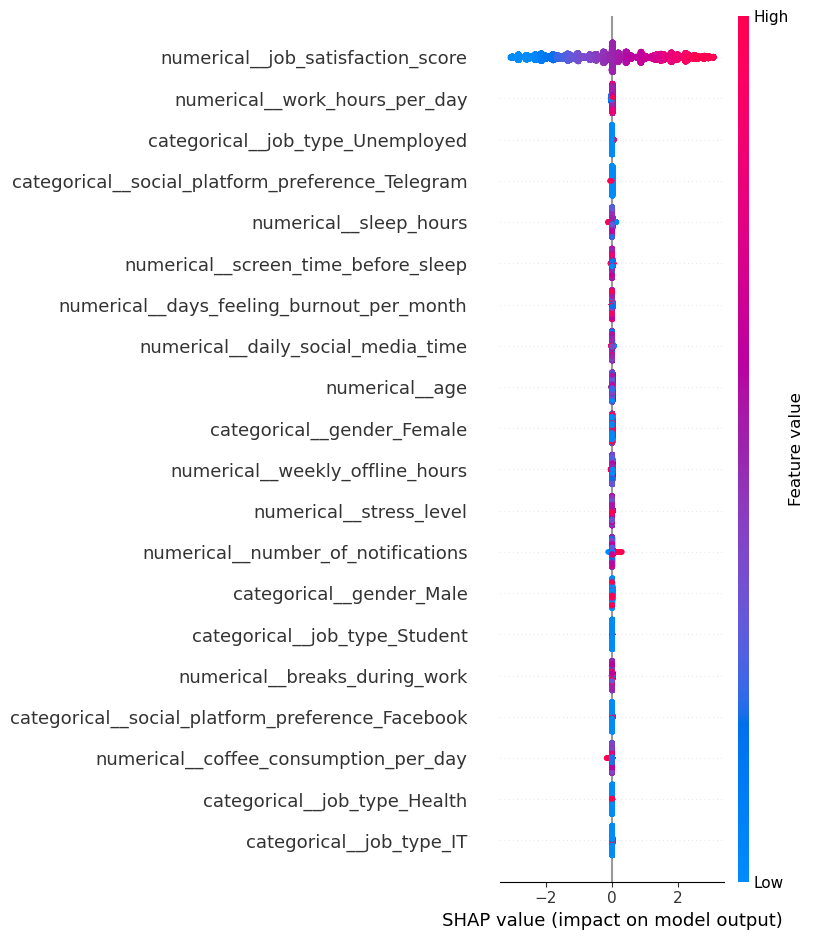

In [96]:
if best_model_name == "XGBoost":

    best_model = xgb_grid.best_estimator_

    X_train_transformed = (
        best_model
        .named_steps["preprocessor"]
        .transform(X_train)
    )

    feature_names = (
        best_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    X_train_transformed_df = pd.DataFrame(
        X_train_transformed,
        columns=feature_names,
        index=X_train.index
    )

    explainer = shap.TreeExplainer(
        best_model.named_steps["model"]
    )

    shap_values = explainer(
        X_train_transformed_df
    )

    shap.summary_plot(
        shap_values,
        X_train_transformed_df
    )

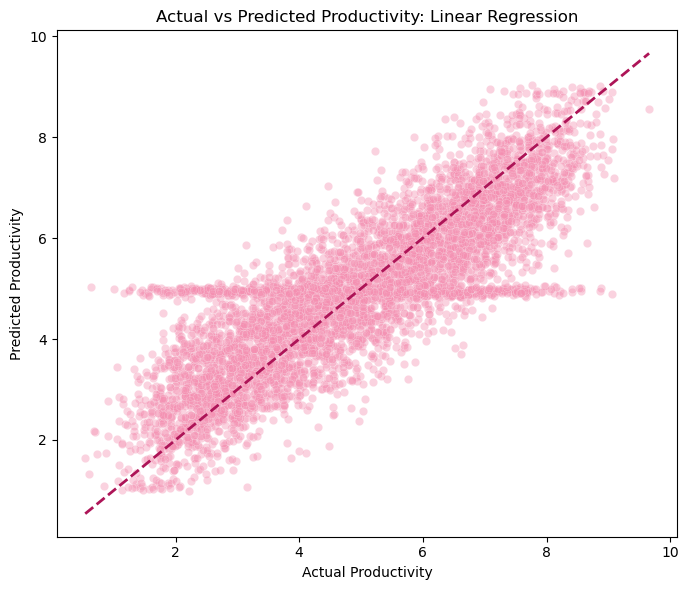

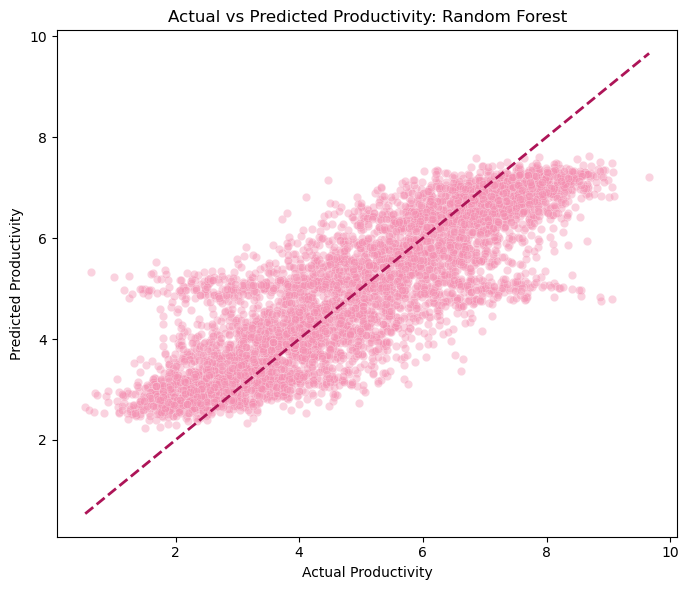

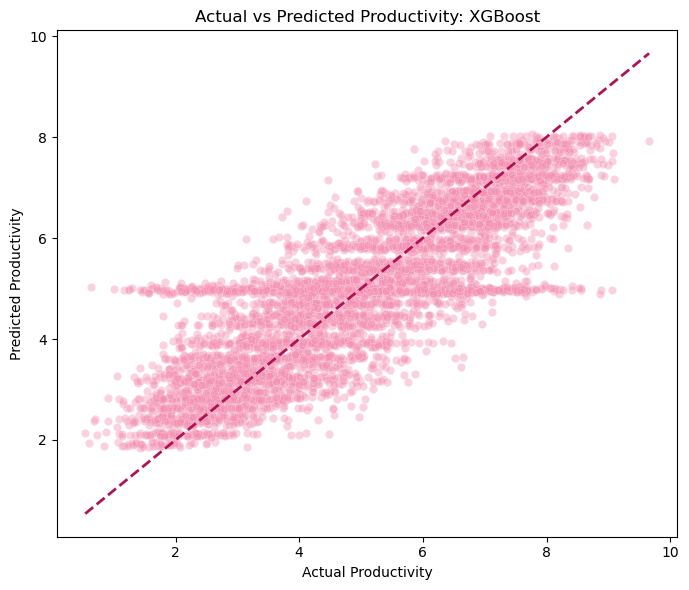

In [97]:
for name, model in final_models.items():

    predictions = model.predict(X_test)

    plt.figure(figsize=(7, 6))

    plt.scatter(
        y_test,
        predictions,
        alpha=0.4, 
        color="#F48FB1",
        edgecolor="white",
        linewidth=0.3
    )

    minimum = min(
        y_test.min(),
        predictions.min()
    )

    maximum = max(
        y_test.max(),
        predictions.max()
    )

    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--",
        color="#AD1457",
        linewidth=2,
        label="Perfect Prediction"
    )

    plt.xlabel("Actual Productivity")
    plt.ylabel("Predicted Productivity")
    plt.title(
        f"Actual vs Predicted Productivity: {name}"
    )

    plt.tight_layout()
    plt.show()

In [98]:
residual_results = {}

for name, model in final_models.items():

    predictions = model.predict(X_test)

    residuals = y_test - predictions

    residual_results[name] = residuals

In [99]:
residual_results = {}

models = {
    "Linear Regression": linear_pipeline,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

for name, model in models.items():

    test_pred = model.predict(X_test)

    residuals = y_test - test_pred

    residual_results[name] = {
        "predictions": test_pred,
        "residuals": residuals
    }

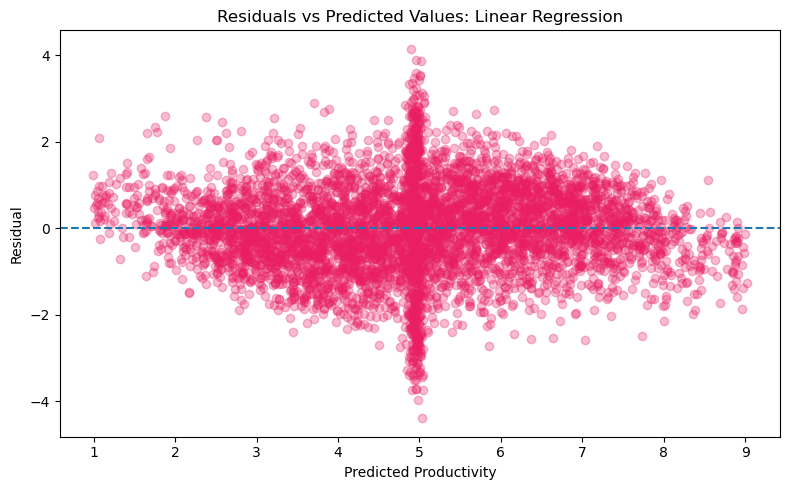

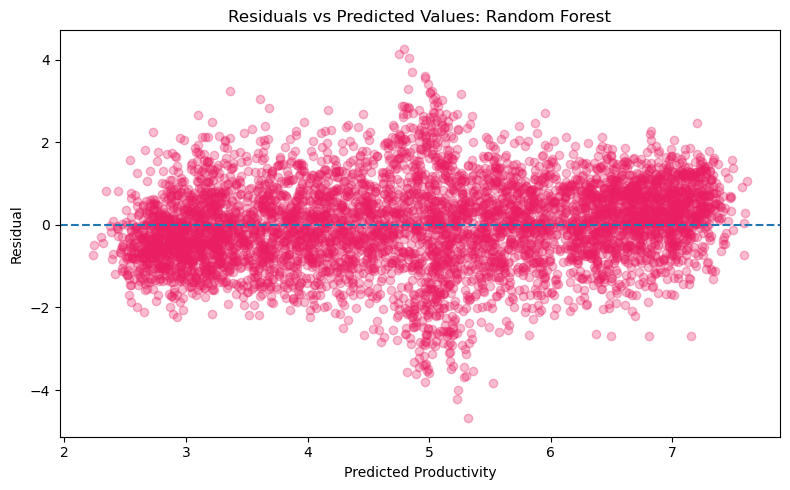

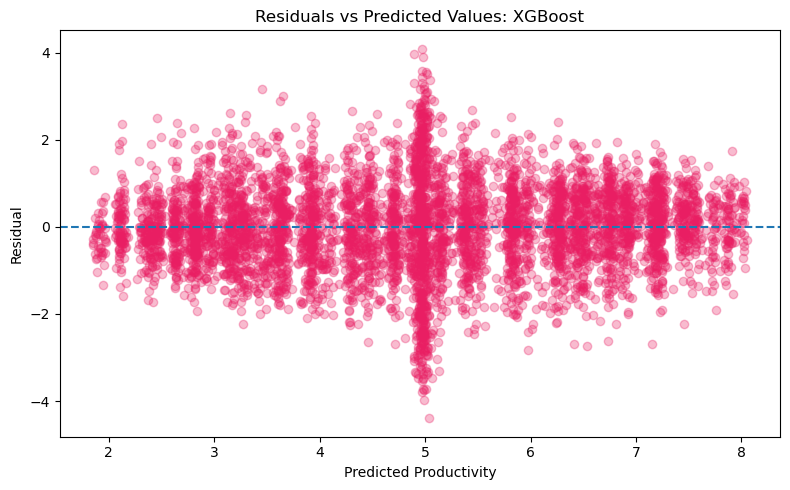

In [101]:
for name, model in final_models.items():

    predictions = model.predict(X_test)
    residuals = y_test - predictions

    plt.figure(figsize=(8, 5))

    plt.scatter(
        predictions,
        residuals,
        alpha=0.3,
        color="#E91E63"
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Predicted Productivity")
    plt.ylabel("Residual")
    plt.title(
        f"Residuals vs Predicted Values: {name}"
    )

    plt.tight_layout()
    plt.show()

In [102]:
social_only_features = [
    "daily_social_media_time",
    "number_of_notifications",
    "social_platform_preference",
    "screen_time_before_sleep",
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

In [103]:
X_social = df_model[social_only_features]
y_social = df_model[TARGET]

In [104]:
# Bools
social_boolean = [
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

# Converting
for column in social_boolean:
    if column in X_social.columns:
        X_social[column] = X_social[column].astype(int)

print(X_social[social_boolean].dtypes)

uses_focus_apps                  int64
has_digital_wellbeing_enabled    int64
dtype: object


In [105]:
X_social_train, X_social_test, y_social_train, y_social_test = train_test_split(
    X_social,
    y_social,
    test_size = 0.20,
    random_state = 42
)

In [106]:
social_numeric = [
    "daily_social_media_time",
    "number_of_notifications",
    "screen_time_before_sleep"
]

social_categorical = [
    "social_platform_preference"
]

social_boolean = [
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

social_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        social_numeric
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        social_categorical
    ),
    (
        "boolean",
        "passthrough",
        social_boolean
    )
])

In [146]:
social_linear = Pipeline([
    ("preprocessor", social_preprocessor),
    ("model", LinearRegression())
])

social_linear.fit(
    X_social_train,
    y_social_train
)

social_predictions = social_linear.predict(
    X_social_test
)

social_r2 = r2_score(
    y_social_test,
    social_predictions
)

social_rmse = np.sqrt(
    mean_squared_error(
        y_social_test,
        social_predictions
    )
)

print("Social-media-only model")
print("R2:", social_r2)
print("RMSE:", social_rmse)

Social-media-only model
R2: -0.00022687970577650596
RMSE: 1.8982514657667144


In [108]:
from sklearn.ensemble import RandomForestRegressor

In [109]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [110]:
rf_train_predictions = rf_pipeline.predict(X_train)
rf_test_predictions = rf_pipeline.predict(X_test)

In [144]:
rf_results_initial = {
    "Model": "Random Forest",
    "Train R2": r2_score(y_train, rf_train_predictions),
    "Test R2": r2_score(y_test, rf_test_predictions),
    "Train MAE": mean_absolute_error(y_train, rf_train_predictions),
    "Test MAE": mean_absolute_error(y_test, rf_test_predictions),
    "Train MSE": mean_squared_error(y_train, rf_train_predictions),
    "Test MSE": mean_squared_error(y_test, rf_test_predictions),
    "Train RMSE": np.sqrt(mean_squared_error(y_train, rf_train_predictions)),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, rf_test_predictions))
}

pd.DataFrame([rf_results_initial])

,Model,Train R2,Test R2,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE
0,Random Forest,0.958849,0.710668,0.292653,0.782822,0.145389,1.042331,0.381299,1.020946


In [112]:
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", 1.0]
}

In [113]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose = 2
)

rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 1.0], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"


In [118]:
print("Best Random Forest parameters:")
print(rf_grid.best_params_)

Best Random Forest parameters:
{'model__max_depth': 5, 'model__max_features': 1.0, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 100}


In [119]:
print("Best Cross Validation RMSE:")
print(-rf_grid.best_score_)

Best Cross Validation RMSE:
1.0016732289634078


In [120]:
best_rf = rf_grid.best_estimator_

rf_train_pred = best_rf.predict(X_train)
rf_test_pred = best_rf.predict(X_test)

In [143]:
rf_results = {
    "Model": "Random Forest",
    "Train R2": r2_score(y_train, rf_train_pred),
    "Test R2": r2_score(y_test, rf_test_pred),
    "Train MAE": mean_absolute_error(y_train, rf_train_pred),
    "Test MAE": mean_absolute_error(y_test, rf_test_pred),
    "Train MSE": mean_squared_error(y_train, rf_train_pred),
    "Test MSE": mean_squared_error(y_test, rf_test_pred),
    "Train RMSE": np.sqrt(mean_squared_error(y_train, rf_train_pred)),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, rf_test_pred))
}

pd.DataFrame([rf_results])

,Model,Train R2,Test R2,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE
0,Random Forest,0.721189,0.718729,0.766765,0.772166,0.985049,1.013292,0.992496,1.006624


#### Random Forest Regression is evaluated as a nonlinear ensemble-learning approach. Unlike Linear Regression, Random Forest can capture complex nonlinear relationships and interactions between predictors without requiring these relationships to be specified in advance


In [122]:
!pip install xgboost

In [123]:
from xgboost import XGBRegressor

In [124]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [125]:
xgb_train_pred = xgb_pipeline.predict(X_train)
xgb_test_pred = xgb_pipeline.predict(X_test)

In [142]:
xgb_results_initial = {
    "Model": "XGBoost",
    "Train R2": r2_score(y_train, xgb_train_pred),
    "Test R2": r2_score(y_test, xgb_test_pred),
    "Train MAE": mean_absolute_error(y_train, xgb_train_pred),
    "Test MAE": mean_absolute_error(y_test, xgb_test_pred),
    "Train RMSE": np.sqrt(mean_squared_error(y_train, xgb_train_pred)),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, xgb_test_pred))
}

pd.DataFrame([xgb_results_initial])

,Model,Train R2,Test R2,Train MAE,Test MAE,Train RMSE,Test RMSE
0,XGBoost,0.720201,0.719233,0.768679,0.771914,0.994254,1.00572


#### XGBoost Regression is evaluated as the third algorithm. XGBoost builds a sequence of decision trees in which each new tree attempts to reduce errors made by the preceding trees. This allows the model to capture complex nonlinear relationships while controlling model complexity through several 


In [127]:
xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

In [128]:
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=2
)

xgb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_grid,"{'model__colsample_bytree': [0.8, 1.0], 'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [3, 5, ...], 'model__n_estimators': [100, 200], ...}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"


In [129]:
print("Best XGBoost parameters:")
print(xgb_grid.best_params_)

Best XGBoost parameters:
{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 1.0}


In [130]:
print("Best XGBoost Cross Validation RMSE:")
print(-xgb_grid.best_score_)

Best XGBoost Cross Validation RMSE:
1.0006974075586297


In [131]:
best_xgb = xgb_grid.best_estimator_

xgb_train_pred = best_xgb.predict(X_train)
xgb_test_pred = best_xgb.predict(X_test)

In [141]:
xgb_results = {
    "Model": "XGBoost",
    "Train R2": r2_score(y_train, xgb_train_pred),
    "Test R2": r2_score(y_test, xgb_test_pred),
    "Train MAE": mean_absolute_error(y_train, xgb_train_pred),
    "Test MAE": mean_absolute_error(y_test, xgb_test_pred),
    "Train MSE": mean_squared_error(y_train, xgb_train_pred),
    "Test MSE": mean_squared_error(y_test, xgb_test_pred),
    "Train RMSE": np.sqrt(mean_squared_error(y_train, xgb_train_pred)),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, xgb_test_pred))
}

pd.DataFrame([xgb_results])

,Model,Train R2,Test R2,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE
0,XGBoost,0.720201,0.719233,0.768679,0.771914,0.988541,1.011473,0.994254,1.00572


### Comparison of 3 models

In [133]:
models = {
    "Linear Regression": linear_pipeline,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

In [140]:
cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV R2": scores["test_r2"].mean(),
        "Std CV R2": scores["test_r2"].std(),
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Std CV RMSE": scores["test_rmse"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Model,Mean CV R2,Std CV R2,Mean CV RMSE,Std CV RMSE
0,Linear Regression,0.708798,0.007859,1.013883,0.014573
1,Random Forest,0.715768,0.007512,1.001673,0.013603
2,XGBoost,0.716325,0.007229,1.000697,0.013171


In [139]:
final_results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred))
    })

final_results_df = pd.DataFrame(final_results)

final_results_df

,Model,Train R2,Test R2,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE
0,Linear Regression,0.709569,0.710228,0.789401,0.789736,1.026102,1.043914,1.012967,1.021721
1,Random Forest,0.721189,0.718729,0.766765,0.772166,0.985049,1.013292,0.992496,1.006624
2,XGBoost,0.720201,0.719233,0.768679,0.771914,0.988541,1.011473,0.994254,1.005720


#### The three algorithms are compared using both five-fold cross-validation and final performance on the unseen test set. R2 measures the proportion of variability in productivity explained by the model, while MAE, MSE, and RMSE quantify prediction error. Higher R2 and lower error values indicate stronger predictive performance.